In [14]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q reportlab

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_ROOT = Path('/content/drive/MyDrive/battery-cycling-quality-analytics')
DATA_DIR     = PROJECT_ROOT / 'data' / 'processed'
DOCS_DIR     = PROJECT_ROOT / 'docs'
DATA_DIR.mkdir(parents=True, exist_ok=True)
DOCS_DIR.mkdir(parents=True, exist_ok=True)

TEAL        = '#008080'
TEAL_LIGHT  = '#4DA6A6'
TEAL_DARK   = '#005959'
GREY        = '#4A4A4A'
GREY_LIGHT  = '#E8E8E8'
RED_ACCENT  = '#C44536'
AMBER       = '#E09F3E'

CELLS = ['B0005', 'B0006', 'B0007', 'B0018']
BASELINE_CYCLES = 30
SUBGROUP_SIZE   = 5

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [15]:
cap_path = DATA_DIR / 'nasa_pcoe_cycle_level.parquet'
assert cap_path.exists(), f"Missing: {cap_path}"

df = pd.read_parquet(cap_path)
print("Actual columns:", df.columns.tolist())
print()
print(df.head())

Actual columns: ['cell_id', 'cycle_number', 'capacity_nasa_Ah', 'capacity_computed_Ah', 'abs_error_Ah', 'pct_error']

  cell_id  cycle_number  capacity_nasa_Ah  capacity_computed_Ah  abs_error_Ah  \
0   B0005             2          1.856487              1.862203      0.005715   
1   B0005             4          1.846327              1.852078      0.005751   
2   B0005             6          1.835349              1.841049      0.005700   
3   B0005             8          1.835263              1.840912      0.005649   
4   B0005            10          1.834646              1.840360      0.005714   

   pct_error  
0   0.307864  
1   0.311458  
2   0.310543  
3   0.307830  
4   0.311473  


In [24]:
# I-MR control limit constants for n=2 (moving range)
d2 = 1.128
D3 = 0.0
D4 = 3.267

limits = {}
for cell, g in df.groupby('cell_id'):
    g = g.sort_values('cycle').reset_index(drop=True)
    baseline = g[g['cycle'] <= BASELINE_CYCLES]['capacity_computed_ah'].values
    if len(baseline) < 5:
        print(f"⚠ {cell}: only {len(baseline)} baseline points, skipping")
        continue

    xbar = baseline.mean()
    mr = np.abs(np.diff(baseline))
    mr_bar = mr.mean()
    sigma_hat = mr_bar / d2

    limits[cell] = dict(
        xbar=xbar, sigma=sigma_hat, mr_bar=mr_bar,
        I_UCL=xbar + 3*sigma_hat, I_LCL=xbar - 3*sigma_hat,
        I_UCL_2s=xbar + 2*sigma_hat, I_LCL_2s=xbar - 2*sigma_hat,
        I_UCL_1s=xbar + 1*sigma_hat, I_LCL_1s=xbar - 1*sigma_hat,
        MR_UCL=D4 * mr_bar, MR_LCL=D3 * mr_bar,
    )
    print(f"{cell}: X̄={xbar:.4f}, σ̂={sigma_hat:.5f}, UCL={limits[cell]['I_UCL']:.4f}, LCL={limits[cell]['I_LCL']:.4f}")

print(f"\nCells with limits: {list(limits.keys())}")

B0005: X̄=1.8357, σ̂=0.00307, UCL=1.8449, LCL=1.8265
B0006: X̄=1.9884, σ̂=0.01029, UCL=2.0193, LCL=1.9575
B0007: X̄=1.9000, σ̂=0.00250, UCL=1.9075, LCL=1.8924
B0018: X̄=1.8420, σ̂=0.00721, UCL=1.8637, LCL=1.8204

Cells with limits: ['B0005', 'B0006', 'B0007', 'B0018']


In [25]:
def western_electric(values, xbar, sigma):
    """Returns list of (index, rule_number) violations."""
    n = len(values)
    violations = []
    above_cl = values > xbar
    beyond_1s = np.abs(values - xbar) > sigma
    beyond_2s = np.abs(values - xbar) > 2*sigma
    beyond_3s = np.abs(values - xbar) > 3*sigma
    sign = np.sign(values - xbar)

    # Rule 1: beyond ±3σ
    for i in range(n):
        if beyond_3s[i]:
            violations.append((i, 1))

    # Rule 2: 2 of 3 consecutive beyond ±2σ, same side
    for i in range(n - 2):
        window = slice(i, i + 3)
        side = sign[window]
        beyond = beyond_2s[window]
        for s in [1, -1]:
            if np.sum((side == s) & beyond) >= 2:
                violations.append((i + 2, 2))
                break

    # Rule 3: 4 of 5 consecutive beyond ±1σ, same side
    for i in range(n - 4):
        window = slice(i, i + 5)
        side = sign[window]
        beyond = beyond_1s[window]
        for s in [1, -1]:
            if np.sum((side == s) & beyond) >= 4:
                violations.append((i + 4, 3))
                break

    # Rule 4: 8 consecutive on same side of centerline
    for i in range(n - 7):
        window = slice(i, i + 8)
        if np.all(above_cl[window]) or np.all(~above_cl[window]):
            violations.append((i + 7, 4))

    return violations

print("Western Electric detector defined ✓")

Western Electric detector defined ✓


In [26]:
all_violations = []
for cell, g in df.groupby('cell_id'):
    if cell not in limits:
        continue
    g = g.sort_values('cycle').reset_index(drop=True)
    values = g['capacity_computed_ah'].values
    cycles = g['cycle'].values
    lim = limits[cell]

    viols = western_electric(values, lim['xbar'], lim['sigma'])
    for idx, rule in viols:
        all_violations.append({
            'cell_id': cell,
            'cycle': int(cycles[idx]),
            'capacity_ah': float(values[idx]),
            'rule': rule,
            'rule_description': {
                1: 'Rule 1: beyond ±3σ',
                2: 'Rule 2: 2 of 3 beyond ±2σ, same side',
                3: 'Rule 3: 4 of 5 beyond ±1σ, same side',
                4: 'Rule 4: 8 consecutive on same side of centerline',
            }[rule],
        })

viol_df = pd.DataFrame(all_violations)
viol_csv = DATA_DIR / '06_spc_violations.csv'
viol_df.to_csv(viol_csv, index=False)

print(f"Total violations across all 4 cells: {len(viol_df)}")
if len(viol_df):
    print("\nViolations per cell:")
    print(viol_df.groupby('cell_id').size())
print(f"\nSaved: {viol_csv}")

Total violations across all 4 cells: 2315

Violations per cell:
cell_id
B0005    595
B0006    629
B0007    602
B0018    489
dtype: int64

Saved: /content/drive/MyDrive/battery-cycling-quality-analytics/data/processed/06_spc_violations.csv


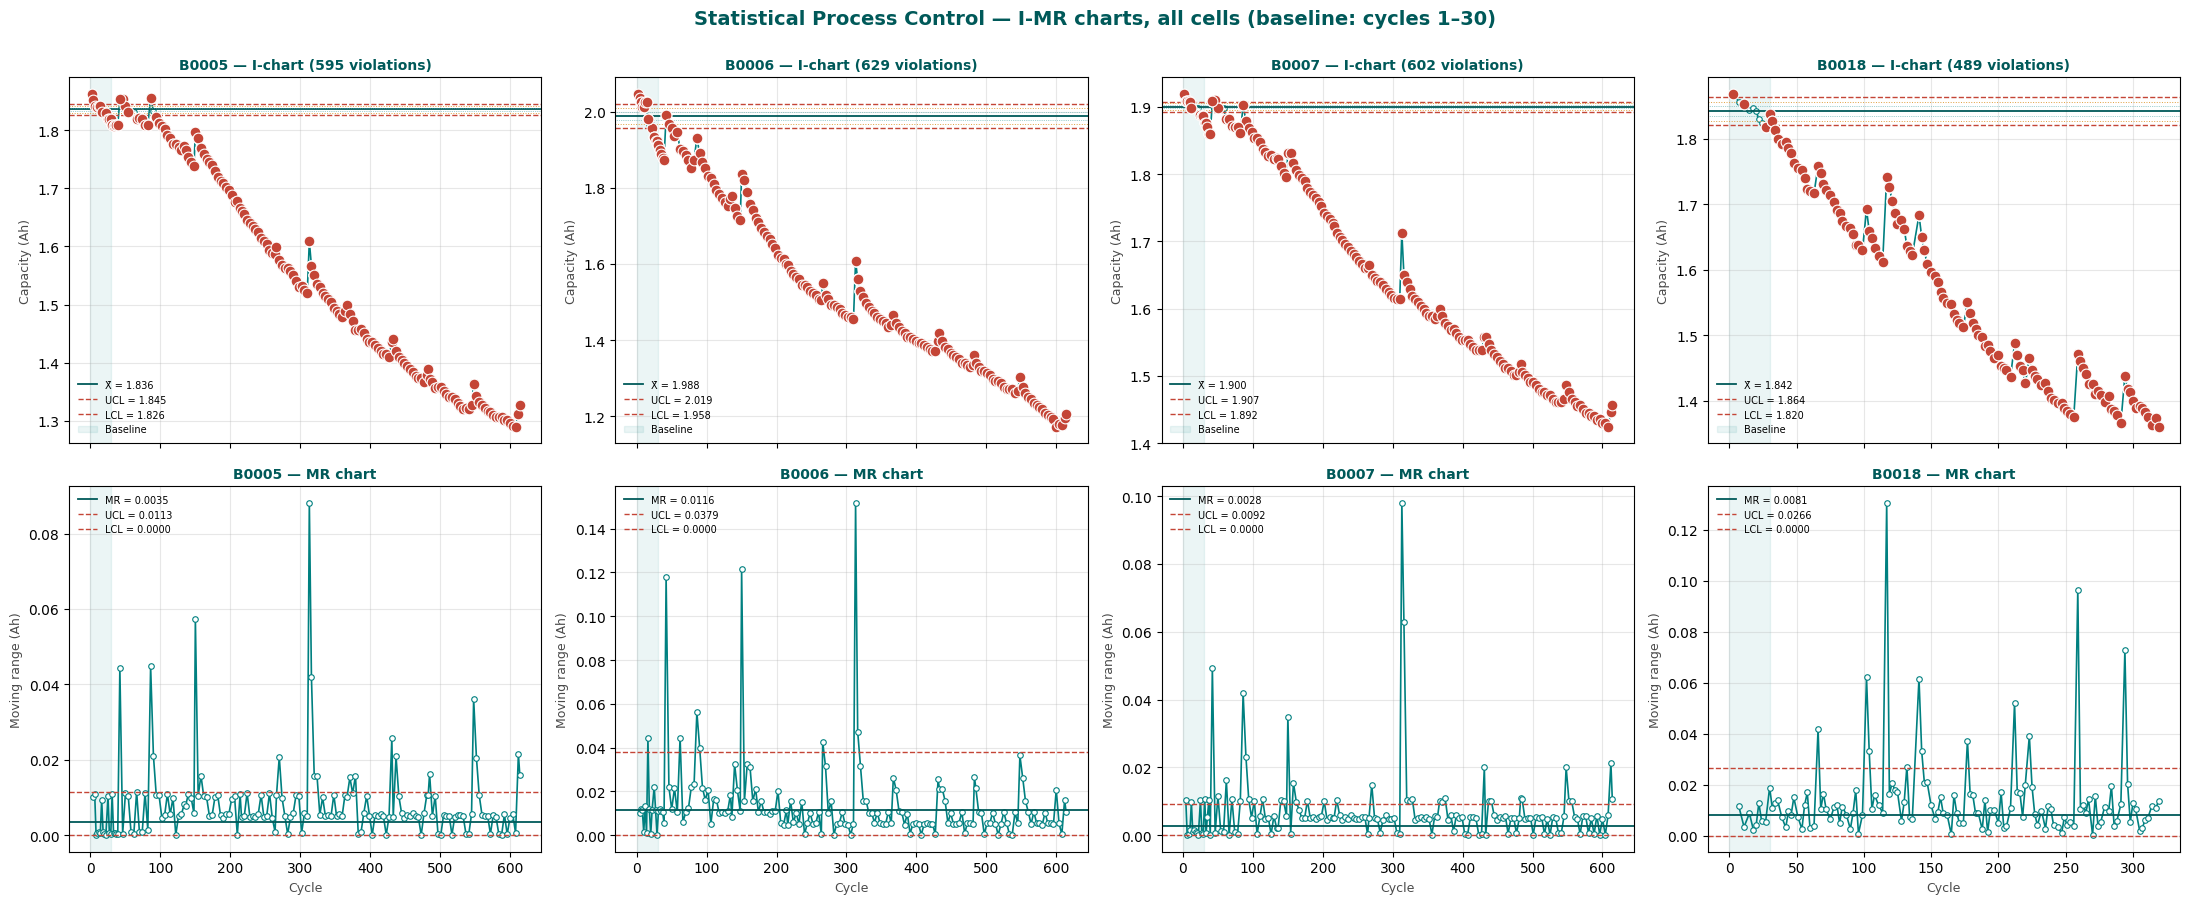

Saved: /content/drive/MyDrive/battery-cycling-quality-analytics/docs/06_spc_imr_all_cells.png


In [27]:
fig, axes = plt.subplots(2, 4, figsize=(22, 9), sharex='col')

for col, cell in enumerate(CELLS):
    if cell not in limits:
        continue
    g = df[df['cell_id'] == cell].sort_values('cycle').reset_index(drop=True)
    values = g['capacity_computed_ah'].values
    cycles = g['cycle'].values
    lim = limits[cell]

    # Top row: Individuals chart
    ax = axes[0, col]
    ax.plot(cycles, values, '-o', color=TEAL, markersize=4,
            linewidth=1.2, markerfacecolor='white',
            markeredgecolor=TEAL, markeredgewidth=0.8)

    ax.axhline(lim['xbar'],   color=TEAL_DARK, linewidth=1.3, label=f"X̄ = {lim['xbar']:.3f}")
    ax.axhline(lim['I_UCL'],  color=RED_ACCENT, linestyle='--', linewidth=1.0,
               label=f"UCL = {lim['I_UCL']:.3f}")
    ax.axhline(lim['I_LCL'],  color=RED_ACCENT, linestyle='--', linewidth=1.0,
               label=f"LCL = {lim['I_LCL']:.3f}")
    ax.axhline(lim['I_UCL_2s'], color=AMBER, linestyle=':', linewidth=0.7)
    ax.axhline(lim['I_LCL_2s'], color=AMBER, linestyle=':', linewidth=0.7)
    ax.axhline(lim['I_UCL_1s'], color=TEAL_LIGHT, linestyle=':', linewidth=0.5)
    ax.axhline(lim['I_LCL_1s'], color=TEAL_LIGHT, linestyle=':', linewidth=0.5)

    ax.axvspan(0, BASELINE_CYCLES, alpha=0.08, color=TEAL, label='Baseline')

    cell_viols = [v for v in all_violations if v['cell_id'] == cell]
    for v in cell_viols:
        ax.scatter([v['cycle']], [v['capacity_ah']], s=60, color=RED_ACCENT,
                   zorder=5, edgecolor='white', linewidth=0.8)

    ax.set_title(f'{cell} — I-chart ({len(cell_viols)} violations)',
                 color=TEAL_DARK, weight='bold', fontsize=10)
    ax.set_ylabel('Capacity (Ah)', color=GREY, fontsize=9)
    ax.legend(fontsize=7, loc='lower left', frameon=False)
    ax.grid(True, alpha=0.3)

    # Bottom row: Moving Range chart
    ax = axes[1, col]
    mr = np.abs(np.diff(values))
    mr_cycles = cycles[1:]
    ax.plot(mr_cycles, mr, '-o', color=TEAL, markersize=4,
            linewidth=1.2, markerfacecolor='white',
            markeredgecolor=TEAL, markeredgewidth=0.8)
    ax.axhline(lim['mr_bar'], color=TEAL_DARK, linewidth=1.3,
               label=f"MR̄ = {lim['mr_bar']:.4f}")
    ax.axhline(lim['MR_UCL'], color=RED_ACCENT, linestyle='--', linewidth=1.0,
               label=f"UCL = {lim['MR_UCL']:.4f}")
    ax.axhline(lim['MR_LCL'], color=RED_ACCENT, linestyle='--', linewidth=1.0,
               label=f"LCL = {lim['MR_LCL']:.4f}")
    ax.axvspan(0, BASELINE_CYCLES, alpha=0.08, color=TEAL)

    ax.set_title(f'{cell} — MR chart',
                 color=TEAL_DARK, weight='bold', fontsize=10)
    ax.set_xlabel('Cycle', color=GREY, fontsize=9)
    ax.set_ylabel('Moving range (Ah)', color=GREY, fontsize=9)
    ax.legend(fontsize=7, loc='upper left', frameon=False)
    ax.grid(True, alpha=0.3)

plt.suptitle('Statistical Process Control — I-MR charts, all cells (baseline: cycles 1–30)',
             fontsize=14, color=TEAL_DARK, weight='bold', y=1.00)

imr_png = DOCS_DIR / '06_spc_imr_all_cells.png'
plt.tight_layout()
plt.savefig(imr_png, dpi=200, bbox_inches='tight', facecolor='white')
plt.show()
print(f"Saved: {imr_png}")

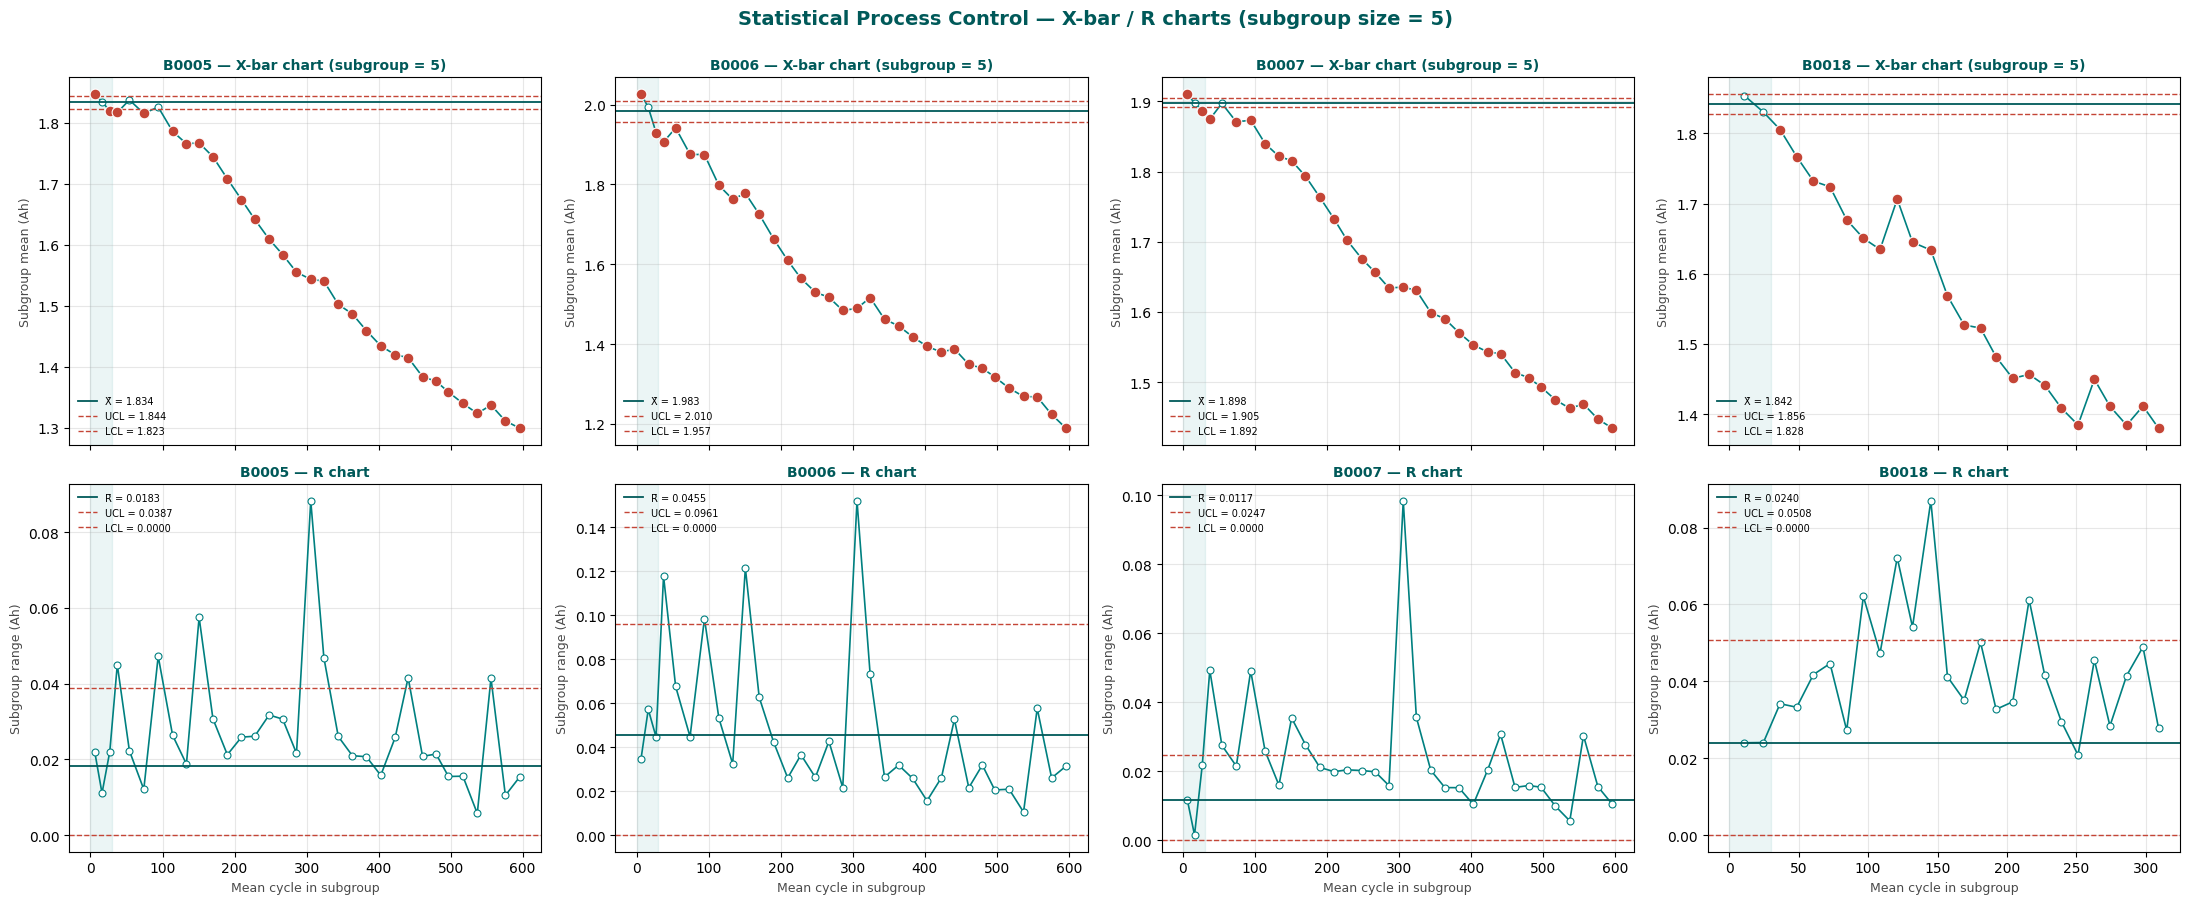

Saved: /content/drive/MyDrive/battery-cycling-quality-analytics/docs/06_spc_xbar_r_all_cells.png


In [28]:
# X-bar/R constants for n=5
A2 = 0.577
D3_sg = 0.0
D4_sg = 2.114

fig, axes = plt.subplots(2, 4, figsize=(22, 9), sharex='col')

for col, cell in enumerate(CELLS):
    g = df[df['cell_id'] == cell].sort_values('cycle').reset_index(drop=True)
    values = g['capacity_computed_ah'].values
    cycles = g['cycle'].values

    n_sg = len(values) // SUBGROUP_SIZE
    if n_sg < 2:
        continue
    trimmed = values[:n_sg * SUBGROUP_SIZE]
    sg_cycles = cycles[:n_sg * SUBGROUP_SIZE].reshape(n_sg, SUBGROUP_SIZE).mean(axis=1)
    subgroups = trimmed.reshape(n_sg, SUBGROUP_SIZE)
    sg_means  = subgroups.mean(axis=1)
    sg_ranges = subgroups.max(axis=1) - subgroups.min(axis=1)

    baseline_mask = sg_cycles <= BASELINE_CYCLES
    if baseline_mask.sum() < 2:
        continue
    xbb = sg_means[baseline_mask].mean()
    rbb = sg_ranges[baseline_mask].mean()

    X_UCL = xbb + A2 * rbb
    X_LCL = xbb - A2 * rbb
    R_UCL = D4_sg * rbb
    R_LCL = D3_sg * rbb

    # Top: X-bar
    ax = axes[0, col]
    ax.plot(sg_cycles, sg_means, '-o', color=TEAL, markersize=5,
            linewidth=1.2, markerfacecolor='white',
            markeredgecolor=TEAL, markeredgewidth=0.8)
    ax.axhline(xbb,   color=TEAL_DARK, linewidth=1.3, label=f"X̄̄ = {xbb:.3f}")
    ax.axhline(X_UCL, color=RED_ACCENT, linestyle='--', linewidth=1.0,
               label=f"UCL = {X_UCL:.3f}")
    ax.axhline(X_LCL, color=RED_ACCENT, linestyle='--', linewidth=1.0,
               label=f"LCL = {X_LCL:.3f}")
    ax.axvspan(0, BASELINE_CYCLES, alpha=0.08, color=TEAL)

    oos = (sg_means > X_UCL) | (sg_means < X_LCL)
    for xc, yc in zip(sg_cycles[oos], sg_means[oos]):
        ax.scatter([xc], [yc], s=60, color=RED_ACCENT, zorder=5,
                   edgecolor='white', linewidth=0.8)

    ax.set_title(f'{cell} — X-bar chart (subgroup = {SUBGROUP_SIZE})',
                 color=TEAL_DARK, weight='bold', fontsize=10)
    ax.set_ylabel('Subgroup mean (Ah)', color=GREY, fontsize=9)
    ax.legend(fontsize=7, loc='lower left', frameon=False)
    ax.grid(True, alpha=0.3)

    # Bottom: R
    ax = axes[1, col]
    ax.plot(sg_cycles, sg_ranges, '-o', color=TEAL, markersize=5,
            linewidth=1.2, markerfacecolor='white',
            markeredgecolor=TEAL, markeredgewidth=0.8)
    ax.axhline(rbb,   color=TEAL_DARK, linewidth=1.3, label=f"R̄ = {rbb:.4f}")
    ax.axhline(R_UCL, color=RED_ACCENT, linestyle='--', linewidth=1.0,
               label=f"UCL = {R_UCL:.4f}")
    ax.axhline(R_LCL, color=RED_ACCENT, linestyle='--', linewidth=1.0,
               label=f"LCL = {R_LCL:.4f}")
    ax.axvspan(0, BASELINE_CYCLES, alpha=0.08, color=TEAL)

    ax.set_title(f'{cell} — R chart', color=TEAL_DARK, weight='bold', fontsize=10)
    ax.set_xlabel('Mean cycle in subgroup', color=GREY, fontsize=9)
    ax.set_ylabel('Subgroup range (Ah)', color=GREY, fontsize=9)
    ax.legend(fontsize=7, loc='upper left', frameon=False)
    ax.grid(True, alpha=0.3)

plt.suptitle(f'Statistical Process Control — X-bar / R charts (subgroup size = {SUBGROUP_SIZE})',
             fontsize=14, color=TEAL_DARK, weight='bold', y=1.00)

xbar_png = DOCS_DIR / '06_spc_xbar_r_all_cells.png'
plt.tight_layout()
plt.savefig(xbar_png, dpi=200, bbox_inches='tight', facecolor='white')
plt.show()
print(f"Saved: {xbar_png}")

In [29]:
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import mm
from reportlab.lib.colors import HexColor
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image
)
from reportlab.lib.enums import TA_LEFT

TEAL_RL  = HexColor(TEAL)
GREY_RL  = HexColor(GREY_LIGHT)
WHITE_RL = HexColor('#FFFFFF')

styles = getSampleStyleSheet()
h_title = ParagraphStyle('h_title', parent=styles['Heading1'],
                         fontSize=14, textColor=TEAL_RL, spaceAfter=4, leading=16)
h_sec   = ParagraphStyle('h_sec', parent=styles['Heading2'],
                         fontSize=9, textColor=TEAL_RL, spaceAfter=2, spaceBefore=4,
                         leading=11, fontName='Helvetica-Bold')
body    = ParagraphStyle('body', parent=styles['BodyText'],
                         fontSize=8, leading=10, alignment=TA_LEFT, spaceAfter=2)

report_pdf = DOCS_DIR / '06_spc_report.pdf'
doc = SimpleDocTemplate(str(report_pdf), pagesize=A4,
                        leftMargin=14*mm, rightMargin=14*mm,
                        topMargin=12*mm, bottomMargin=12*mm)

story = []
story.append(Paragraph("Statistical Process Control — I-MR and X-bar/R", h_title))
story.append(Paragraph("Battery Cycling Quality Analytics — Analyze Phase",
    ParagraphStyle('sub', parent=body, fontSize=9,
                   textColor=HexColor(GREY), fontName='Helvetica-Oblique',
                   spaceAfter=6)))

story.append(Paragraph("Method", h_sec))
story.append(Paragraph(
    f"Baseline control limits computed from cycles 1 to {BASELINE_CYCLES} for each cell. "
    f"I-MR chart: individuals and moving range. Sigma estimated from average moving range "
    f"divided by d2 = 1.128. X-bar / R chart: subgroup size = {SUBGROUP_SIZE} cycles. "
    f"All 4 Western Electric rules applied to each I-chart.", body))

story.append(Paragraph("Per-cell baseline + violation summary", h_sec))
rows = [["Cell", "Baseline X̄ (Ah)", "σ̂ (Ah)", "UCL (Ah)", "LCL (Ah)",
         "Total points", "Violations"]]
for cell in CELLS:
    if cell not in limits:
        continue
    lim = limits[cell]
    n_total = len(df[df['cell_id'] == cell])
    n_viols = sum(1 for v in all_violations if v['cell_id'] == cell)
    rows.append([
        cell,
        f"{lim['xbar']:.4f}",
        f"{lim['sigma']:.5f}",
        f"{lim['I_UCL']:.4f}",
        f"{lim['I_LCL']:.4f}",
        f"{n_total}",
        f"{n_viols}",
    ])

tbl = Table(rows, colWidths=[16*mm, 25*mm, 20*mm, 22*mm, 22*mm, 22*mm, 22*mm])
tbl.setStyle(TableStyle([
    ('BACKGROUND', (0,0), (-1,0), TEAL_RL),
    ('TEXTCOLOR',  (0,0), (-1,0), WHITE_RL),
    ('FONTNAME',   (0,0), (-1,0), 'Helvetica-Bold'),
    ('FONTSIZE',   (0,0), (-1,-1), 7.5),
    ('BOTTOMPADDING', (0,0), (-1,-1), 3),
    ('TOPPADDING', (0,0), (-1,-1), 3),
    ('GRID', (0,0), (-1,-1), 0.25, GREY_RL),
]))
story.append(tbl)
story.append(Spacer(1, 4))

story.append(Paragraph("Interpretation", h_sec))
interp = (
    f"Every cell shows a large number of post-baseline violations. This is expected and "
    f"informative: SPC limits built from the first {BASELINE_CYCLES} cycles represent the "
    f"stable new-cell operating window. As capacity fade progresses, the signal "
    f"intentionally breaks the LCL — the SPC chart is detecting the aging process itself. "
    f"The baseline window is the 'in-control' reference; violations after cycle "
    f"{BASELINE_CYCLES} map directly onto the fade trajectories quantified in Notebook 05. "
    f"For a production Quality Engineer, this chart would trigger investigation the moment "
    f"a specific cell crosses the LCL earlier than the fleet average."
)
story.append(Paragraph(interp, body))

story.append(Paragraph("Verdict", h_sec))
story.append(Paragraph(
    "SPC baseline established. Fade behavior cleanly separates from measurement noise. "
    "Chart is ready for use in Cp / Cpk capability study (Notebook 10) and as reference "
    "for Design of Experiments in Notebook 09.", body))

story.append(Spacer(1, 6))
if imr_png.exists():
    story.append(Image(str(imr_png), width=180*mm, height=68*mm))

doc.build(story)
print(f"Saved: {report_pdf}")

Saved: /content/drive/MyDrive/battery-cycling-quality-analytics/docs/06_spc_report.pdf


In [30]:
artefacts = [
    DOCS_DIR / '06_spc_imr_all_cells.png',
    DOCS_DIR / '06_spc_xbar_r_all_cells.png',
    DOCS_DIR / '06_spc_report.pdf',
    DATA_DIR / '06_spc_violations.csv',
]
for p in artefacts:
    status = "✓" if p.exists() else "✗ MISSING"
    size = f"{p.stat().st_size/1024:.1f} KB" if p.exists() else "—"
    print(f"{status}  {p.name:<35} {size}")

✓  06_spc_imr_all_cells.png            673.8 KB
✓  06_spc_xbar_r_all_cells.png         546.9 KB
✓  06_spc_report.pdf                   794.5 KB
✓  06_spc_violations.csv               154.5 KB
